# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Tumour-Board Briefing

### Scenario

You are the visualization engineer in the **3-D Imaging Lab at City General Hospital**. Tomorrow morning the
neuro-oncology **tumour board** (a neurosurgeon, a radiologist and an oncologist) will review a patient's head CT
(`unit3_ppt3_head_ct_phantom.csv`). The lab head forwards you four requests:

1. **IT department:** *"The new scanner protocol is 512 × 512 × 300 at 0.5 × 0.5 × 1.0 mm. How much storage per scan,
   and how many samples does one volume-rendered frame cost?"*
2. **Radiologist:** *"Show me the lesion in all three planes, at its centre, with the anatomy undistorted."*
3. **Neurosurgeon:** *"I need the tumour volume in mL — and I want to know how much that number depends on the
   threshold you picked."*
4. **Oncologist:** *"Your last 3-D render showed a beautiful skull and nothing else. I need to see the tumour and its
   relation to the ventricles."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your
own words. The ground-truth `labels` array may be used **only to evaluate** your results, never to find the tumour.

## Part 0 — Setup (given)

Run this cell as-is. It loads the volume `vol[z, y, x]`, the evaluation-only `labels`, the voxel spacing, and two
helpers: `make_tf(points)` builds a transfer function from `(hu, (r, g, b), alpha)` control points, and
`render(volume, tf, axis)` ray-casts the volume with front-to-back compositing (resampled at 2× density).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ct = pd.read_csv("unit3_ppt3_head_ct_phantom.csv")
NZ, NY, NX = ct.z.max() + 1, ct.y.max() + 1, ct.x.max() + 1
vol = ct.intensity_hu.values.reshape(NZ, NY, NX)        # V[z, y, x]  (z = feet->head, y = front->back, x = left->right)
labels = ct.label.values.reshape(NZ, NY, NX)            # ground truth: 0 air, 1 scalp, 2 bone, 3 brain, 4 CSF, 5 tumour
SPACING = (4.0, 3.0, 3.0)                               # voxel size in mm along (z, y, x)
VOXEL_MM3 = np.prod(SPACING)
ASPECT = SPACING[0] / SPACING[2]                        # use when z is on a screen axis

def make_tf(points):
    # points: list of (hu, (r, g, b), alpha) control points -> transfer function T(s) -> (C, alpha)
    hu = np.array([p[0] for p in points], float)
    rgb = np.array([p[1] for p in points], float)
    alpha = np.array([p[2] for p in points], float)
    def tf(s):
        c = np.stack([np.interp(s, hu, rgb[:, k]) for k in range(3)], axis=-1)
        return c, np.interp(s, hu, alpha)
    return tf

def render(volume, tf, axis=1, upsample=2):
    # Orthographic ray casting with front-to-back compositing; rays travel along `axis`.
    # upsample=2 resamples the volume trilinearly at twice the density (smoother, fewer aliasing artifacts).
    v = ndimage.zoom(volume.astype(float), upsample, order=1) if upsample > 1 else volume
    v = np.moveaxis(v, axis, 0)
    C = np.zeros(v.shape[1:] + (3,)); A = np.zeros(v.shape[1:])
    for sample in v:                                    # one sample per voxel step along every ray at once
        c, a = tf(sample)
        C += ((1 - A) * a)[..., None] * c
        A += (1 - A) * a
    return C, A

print(f"vol {vol.shape} (z, y, x), voxel {SPACING} mm, {VOXEL_MM3:.0f} mm^3 per voxel")

vol (48, 64, 64) (z, y, x), voxel (4.0, 3.0, 3.0) mm, 36 mm^3 per voxel


## Task 1 — The IT Department's Numbers (Request #1)

**Real-world usage:** PACS storage and GPU sizing for 3-D workstations are budgeted from exactly these figures.

**Why this technique:** Voxel count = Nx·Ny·Nz (Slides 7, 12); each ray samples the volume at successive positions
(Slide 22), so one frame costs ≈ rays × samples per ray; early ray termination skips samples once α_acc → 1
(Slide 27).

**TODO:**
1. Number of voxels in a 512 × 512 × 300 scan, and its size in MB at 16 bits per voxel.
2. Physical size of the scanned region in mm, and the volume of one voxel in mm³ (0.5 × 0.5 × 1.0 mm).
3. Samples needed for ONE front-view rendered frame (one ray per x–z pixel, one sample per voxel step in y), and
   for a 360° rotation video of 120 frames.
4. If early ray termination stops rays after 35% of their samples on average, how many samples does the 120-frame
   video need instead?

In [2]:
# TODO 1
n_voxels = 512 * 512 * 300
scan_mb = n_voxels * 2 / 1024**2          # 16 bits = 2 bytes per voxel

# TODO 2
extent_mm = (512 * 0.5, 512 * 0.5, 300 * 1.0)          # (x, y, z) in mm
voxel_mm3 = 0.5 * 0.5 * 1.0

# TODO 3
samples_per_frame = 512 * 300 * 512       # one ray per x-z pixel, 512 samples along y
samples_video = samples_per_frame * 120

# TODO 4
samples_video_ert = samples_video * 0.35

print(f"{n_voxels:,} voxels = {scan_mb:.1f} MB | extent {extent_mm} mm | voxel {voxel_mm3} mm^3")
print(f"samples/frame {samples_per_frame:,} | 120 frames {samples_video:,} | with early termination {samples_video_ert:,.0f}")

78,643,200 voxels = 150.0 MB | extent (256.0, 256.0, 300.0) mm | voxel 0.25 mm^3
samples/frame 78,643,200 | 120 frames 9,437,184,000 | with early termination 3,303,014,400


**Reflection:** The new protocol has *anisotropic* voxels (0.5 × 0.5 × 1.0 mm). What two things would go wrong in the
radiologist's coronal and sagittal views if the software ignored that (Slides 8–10)?

_Your answer:_

If the software ignored the 0.5 × 0.5 × 1.0 mm spacing and drew voxels as squares: (1) the coronal and sagittal views would be **geometrically distorted**, with everything along z squashed to half its true height (heads look flat, a round lesion becomes an ellipse); (2) any **measurement taken in voxel units** (distances, areas, volume) would be wrong, because a step in z is twice as long as a step in x or y. The fix is to display with the correct aspect ratio (`aspect = dz/dx`), as I did with `aspect=ASPECT`.

## Task 2 — Find the Lesion and Show It in Three Planes (Request #2)

**Real-world usage:** Every radiology workstation opens on a 3-plane MPR with linked cross-hairs.

**Why this technique:** **Orthogonal slices / MPR** give complementary views of the same structure (Slides 15–17);
a **window/level** setting is the slice-display transfer function; the correct **voxel aspect ratio** keeps anatomy
undistorted (Slide 9).

**TODO:**
1. Find the lesion *without* `labels`: take voxels with 55 < HU < 90 that lie **inside the brain** — use
   `inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)` and erode it 3 times
   (`ndimage.binary_erosion(..., iterations=3)`) to avoid the partial-volume shell under the skull.
2. Keep the largest connected component (`ndimage.label`) and compute its centroid (z, y, x) as integers.
3. Plot axial, coronal and sagittal slices through that centroid with cross-hairs, a brain window (W = 80, L = 40),
   and `aspect=ASPECT` for the two views that contain z.
4. Evaluation only: print how far (in mm) your centroid is from the centroid of `labels == 5`.

lesion centroid (z, y, x) = (28, 40, 41) | voxels: 431


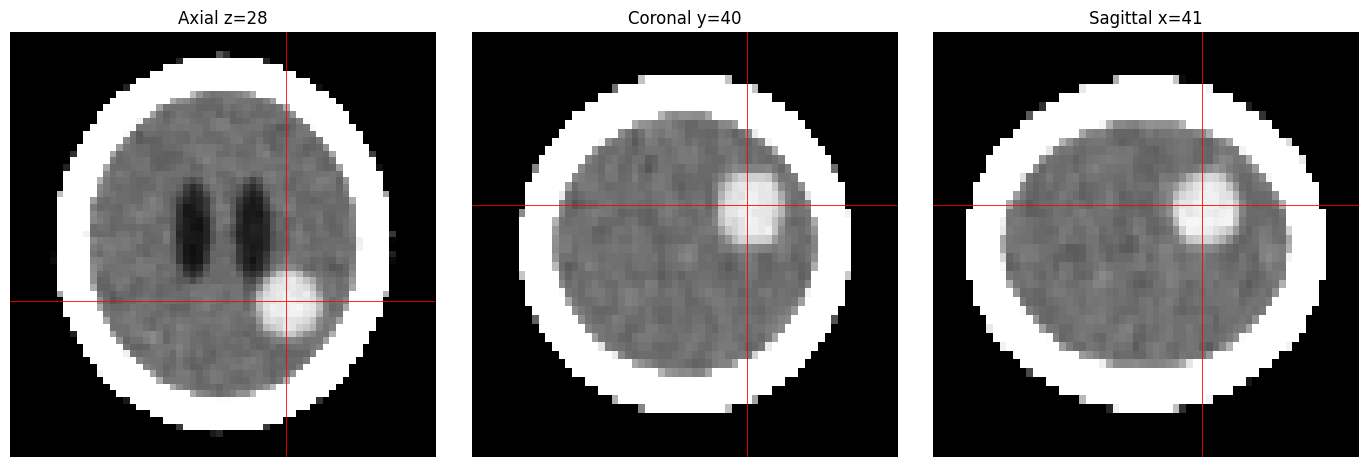

Distance to the true tumour centroid: 2.92 mm


In [3]:
def window(a, W, L):
    return np.clip((a - (L - W / 2)) / W, 0, 1)

# TODO 1
skull = vol > 300
inside = ndimage.binary_fill_holes(skull) & ~skull
inside = ndimage.binary_erosion(inside, iterations=3)
candidates = inside & (vol > 55) & (vol < 90)

# TODO 2
lab, n = ndimage.label(candidates)
sizes = ndimage.sum(candidates, lab, range(1, n + 1))
lesion = lab == (1 + int(np.argmax(sizes)))
cz, cy, cx = [int(round(v)) for v in ndimage.center_of_mass(lesion)]
print("lesion centroid (z, y, x) =", (cz, cy, cx), "| voxels:", int(lesion.sum()))

# TODO 3
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
axes[0].imshow(window(vol[cz], 80, 40), cmap="gray"); axes[0].set_title(f"Axial z={cz}")
axes[0].axhline(cy, c="r", lw=.6); axes[0].axvline(cx, c="r", lw=.6)
axes[1].imshow(window(vol[:, cy, :], 80, 40), cmap="gray", aspect=ASPECT, origin="lower"); axes[1].set_title(f"Coronal y={cy}")
axes[1].axhline(cz, c="r", lw=.6); axes[1].axvline(cx, c="r", lw=.6)
axes[2].imshow(window(vol[:, :, cx], 80, 40), cmap="gray", aspect=ASPECT, origin="lower"); axes[2].set_title(f"Sagittal x={cx}")
axes[2].axhline(cz, c="r", lw=.6); axes[2].axvline(cy, c="r", lw=.6)
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

# TODO 4 (evaluation only)
true_c = np.array(ndimage.center_of_mass(labels == 5))
d = np.linalg.norm((true_c - np.array([cz, cy, cx])) * np.array(SPACING))
print(f"Distance to the true tumour centroid: {d:.2f} mm")

**Reflection:** Why did you need the erosion step? Explain in terms of the **partial-volume effect** and the
overlapping intensity ranges the lecture lists as a transfer-function challenge (Slide 28).

_Your answer:_

Voxels at the brain-skull boundary (and brain-CSF boundary) are a mixture of brain (~36 HU) and bone (~740 HU), so by the **partial-volume effect** their values sweep through every number in between, including the 55-90 HU range of the tumour (tumour voxels are 49-77 HU). Tissue classes therefore have **overlapping intensity ranges** (Slide 28), and thresholding on HU alone picks up a thin shell of false candidates around the whole brain. Eroding the brain mask 3 times removes that 1-2 voxel thick shell but leaves the thick tumour blob, so the largest connected component is the lesion: centroid (z, y, x) = (28, 40, 41), 431 voxels, 2.92 mm from the true centroid (evaluation only).

## Task 3 — Tumour Volume and Its Threshold Sensitivity (Request #3)

**Real-world usage:** Tumour volume drives treatment decisions and response assessment, so its uncertainty must be
reported.

**Why this technique:** An **isosurface/segmentation at threshold c** defines the structure — and *the chosen c
strongly influences the resulting geometry* (Slides 19–20, 31–32).

**TODO:**
1. For c in `[45, 50, 55, 60, 65, 70]`, grow the region `vol > c` from your lesion centre (connected component
   containing `(cz, cy, cx)`).
2. For each c, record the voxel count, the volume in mL (`voxels * VOXEL_MM3 / 1000`), and — evaluation only — the
   Dice overlap with `labels == 5`.
3. Plot volume (mL) vs. threshold, and mark the threshold with the best Dice.
4. Print the range of volumes you would report to the surgeon.

,threshold,voxels,volume_mL,dice
0,45,535,19.26,0.929
1,50,464,16.70,0.994
2,55,431,15.52,0.963
3,60,350,12.60,0.860
4,65,273,9.83,0.741
5,70,170,6.12,0.536


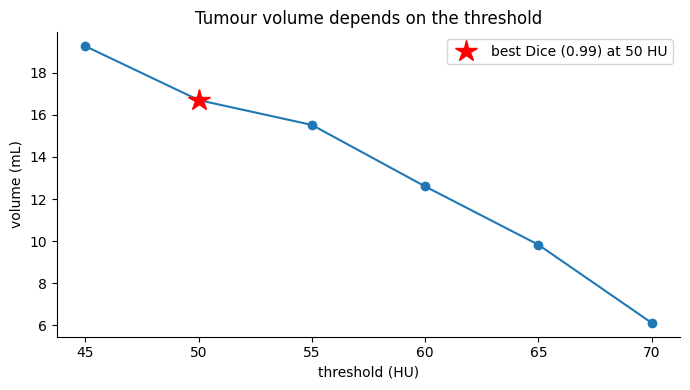

Report to the surgeon: 12.6-19.3 mL (thresholds 45-60 HU); best-Dice threshold 50 HU -> 16.7 mL. Full sweep 45-70 HU: 6.1-19.3 mL.


In [4]:
truth = labels == 5
rows = []
# TODO 1 & 2
for c in [45, 50, 55, 60, 65, 70]:
    l2, _ = ndimage.label(vol > c)
    region = l2 == l2[cz, cy, cx]
    nv = int(region.sum())
    dice = 2 * (region & truth).sum() / (region.sum() + truth.sum())
    rows.append(dict(threshold=c, voxels=nv, volume_mL=round(nv * VOXEL_MM3 / 1000, 2), dice=round(float(dice), 3)))

table = pd.DataFrame(rows)
display(table)

# TODO 3
best = table.loc[table.dice.idxmax()]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(table.threshold, table.volume_mL, "-o")
ax.plot(best.threshold, best.volume_mL, "r*", ms=16, label=f"best Dice ({best.dice:.2f}) at {int(best.threshold)} HU")
ax.set(xlabel="threshold (HU)", ylabel="volume (mL)", title="Tumour volume depends on the threshold"); ax.legend()
plt.tight_layout(); plt.show()

# TODO 4
ok = table[table.threshold <= 60]
print(f"Report to the surgeon: {ok.volume_mL.min():.1f}-{ok.volume_mL.max():.1f} mL (thresholds 45-60 HU); "
      f"best-Dice threshold {int(best.threshold)} HU -> {best.volume_mL:.1f} mL. Full sweep 45-70 HU: {table.volume_mL.min():.1f}-{table.volume_mL.max():.1f} mL.")

**Reflection:** In real life there is no ground-truth label. How would you choose and justify c for the tumour
board, and how would you *visualize* the uncertainty so the surgeon doesn't treat a single number as exact?

_Your answer:_

Without ground truth I would not pick c from the labels but from the data: choose a threshold about half-way between the surrounding brain (~36 HU) and the tumour core (~65-70 HU), which is about 50 HU, check how much the volume moves around it, then verify by overlaying the contour on the axial/coronal/sagittal slices and have the radiologist confirm it. I would never give one number: report the range (12.6-19.3 mL for 45-60 HU; best Dice was at 50 HU = 16.7 mL) and **visualize the uncertainty**, for example nested iso-contours for 45/50/55/60 HU on the slices and the volume-vs-threshold curve with a shaded band, so the surgeon sees how much the answer moves with c.

## Task 4 — A 3-D Render That Shows the Tumour (Request #4)

**Real-world usage:** Pre-operative 3-D views show a lesion in context with critical structures (here the ventricles).

**Why this technique:** **Direct volume rendering** with a designed **transfer function** — colour to *identify*
materials, opacity to *reveal or suppress* them (Slides 21–27); occlusion is the main enemy (Slide 28).

**TODO:**
1. Render the given `bone_tf` (front view, `axis=1`) — this is the "beautiful skull" the oncologist complained about.
2. Design your own `tumour_tf` with `make_tf([...])` so that: air and soft tissue are fully transparent, bone is
   *almost* transparent (α ≤ 0.01, still gives context), CSF (≈ 5–20 HU) is blue and faint, and the tumour range
   is red. Remember that opacity **accumulates over every sample along a ray**: a thick structure with α ≈ 0.1
   per sample becomes nearly opaque, while a thin one stays faint — use that to your advantage.
3. Render your TF from the front (`axis=1`) **and** from above (`axis=0`), side by side with the bone render.
4. Give the figure a conclusion-style title.

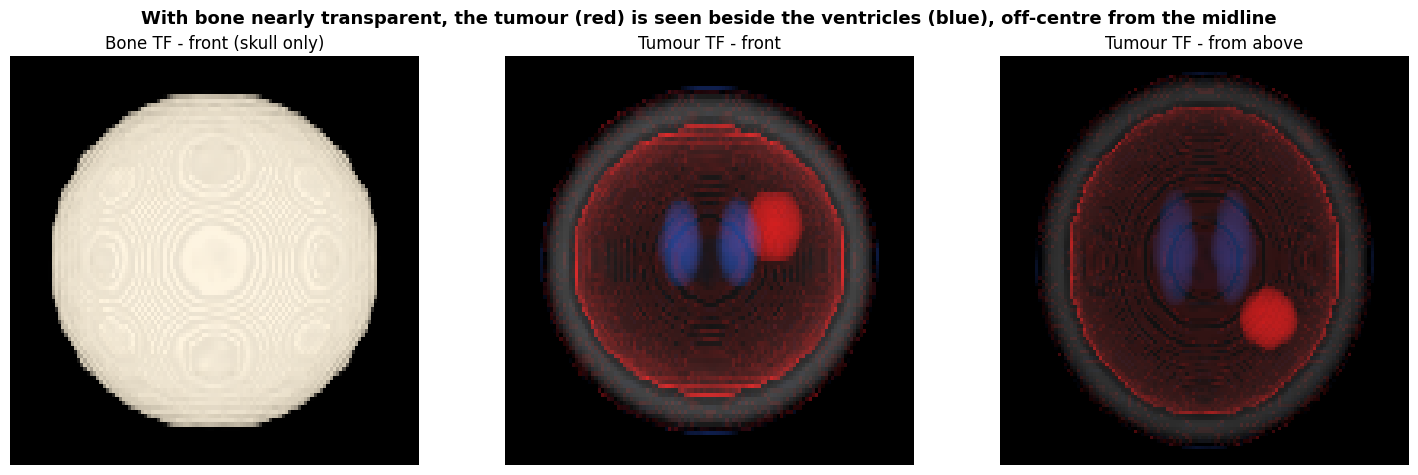

In [5]:
bone_tf = make_tf([(-1000, (0, 0, 0), 0), (200, (0, 0, 0), 0), (400, (1, 0.95, 0.85), 0.3), (1500, (1, 1, 1), 0.6)])

# TODO 2: your transfer function (air/soft tissue transparent, bone almost transparent, CSF faint blue, tumour red)
tumour_tf = make_tf([(-1000, (0, 0, 0), 0), (-5, (0, 0, 0), 0), (5, (.2, .4, 1), .02), (20, (.2, .4, 1), .02), (30, (0, 0, 0), 0),
                     (52, (0, 0, 0), 0), (58, (1, .1, .1), .07), (80, (1, .1, .1), .07), (90, (0, 0, 0), 0),
                     (250, (0, 0, 0), 0), (400, (1, 1, 1), .004), (1500, (1, 1, 1), .01)])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
# TODO 1 & 3: bone render | your TF front view | your TF top view
Cb, Ab = render(vol, bone_tf, 1); Cf, Af = render(vol, tumour_tf, 1); Ct, At = render(vol, tumour_tf, 0)
axes[0].imshow(np.clip(Cb, 0, 1), origin="lower", aspect=ASPECT); axes[0].set_title("Bone TF - front (skull only)")
axes[1].imshow(np.clip(Cf, 0, 1), origin="lower", aspect=ASPECT); axes[1].set_title("Tumour TF - front")
axes[2].imshow(np.clip(Ct, 0, 1), origin="upper"); axes[2].set_title("Tumour TF - from above")
for a in axes: a.axis("off")

# TODO 4: suptitle
fig.suptitle("With bone nearly transparent, the tumour (red) is seen beside the ventricles (blue), off-centre from the midline", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()

**Reflection:** Your tumour TF probably also lights up a faint red rim just inside the skull. Which volume-rendering
challenge from Slide 28 causes it? Name one technique from this lecture (hint: Slides 31–32) that would remove it,
and explain why a transfer function alone cannot.

_Your answer:_

The faint red rim is caused by the **partial-volume effect / overlapping intensity ranges** (Slide 28): on every ray, the transition from brain to bone passes through the tumour's HU range, so the thin boundary shell gets the tumour colour and a little opacity. Segmentation (Slides 31-32), i.e. masking the volume to the connected tumour region before rendering, removes it. A transfer function alone cannot, because it is a function of intensity only: a boundary voxel and a real tumour voxel with the same HU get exactly the same colour and opacity, and nothing in T(s) knows *where* the voxel is or what it is connected to.

## Task 5 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the tumour board covering the whole notebook. It should:
- State where the lesion is and its volume **as a range** (Task 3), in plain language.
- Recommend which **one** view to open the meeting with (MPR, segmentation overlay, or the 3-D render) and justify
  it with at least one lecture idea (occlusion, slicing exposes internal structure, transfer-function overlap,
  segmentation enables measurement).
- Name one limitation of the 3-D render the board should keep in mind.

_Your final note here:_

The lesion is an off-centre mass next to the ventricles, centred at voxel (z, y, x) = (28, 40, 41), with a volume of roughly 13-19 mL depending on the threshold (12.6 mL at 60 HU, 16.7 mL at 50 HU, 19.3 mL at 45 HU); the best estimate is about 15-17 mL. I would open the meeting with the **three-plane MPR with the segmentation outline**, because slicing exposes the internal structure directly, the segmentation is what makes the volume measurable, and the board can check the contour against the actual HU on every plane; the 3-D render is fighting occlusion and cannot be measured from. The limitation of the 3-D render to keep in mind is that it shows only what the transfer function chooses to show: opacity accumulates along the ray so apparent size and depth are subjective, and a faint rim of partial-volume artefact can look like tissue, so it is for orientation, not for measurement.